In [2]:
import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt



def load_tiff_frame(path, index):
    """Load one frame (page) from a multi-page TIFF without reading the rest."""
    with tifffile.TiffFile(path) as tif:
        n = len(tif.pages)
        if not -n <= index < n:
            raise IndexError(f"Frame {index} out of range (file has {n} frames)")
        return tif.pages[index].asarray(),n

In [21]:
import numpy as np
from scipy.ndimage import map_coordinates


def angular_profile(img, x0, y0, r, n_angles=None, width=0.0, n_radii=5, order=1):
    """Intensity around a circle of radius r centred on (x0, y0).

    img:      2D array, indexed img[y, x]
    x0, y0:   centre (column, row), may be fractional
    r:        radius in pixels
    n_angles: number of angular samples (default about one per pixel of arc, 2*pi*r)
    width:    radial thickness of the ring; values from r - width/2 to r + width/2
              are averaged at each angle (0 = just the circle)
    n_radii:  how many radii to average across the ring when width > 0
    order:    interpolation order (1 = bilinear, 3 = cubic)

    Returns (angles_deg, profile). Angle 0 points along +x and increases towards +y
    (clockwise on screen, since imshow puts y = 0 at the top).
    """
    img = np.asarray(img, dtype=np.float64)
    if n_angles is None:
        n_angles = max(int(np.ceil(2 * np.pi * r)), 8)

    theta = np.linspace(0, 2 * np.pi, n_angles, endpoint=False)
    radii = np.linspace(r - width / 2, r + width / 2, n_radii) if width > 0 else np.array([r])

    # sample coordinates: shape (n_radii, n_angles)
    ys = y0 + radii[:, None] * np.sin(theta)[None, :]
    xs = x0 + radii[:, None] * np.cos(theta)[None, :]

    # points off the image come back as NaN
    vals = map_coordinates(img, [ys.ravel(), xs.ravel()], order=order,
                           mode="constant", cval=np.nan).reshape(ys.shape)
    profile = np.nanmean(vals, axis=0)
    return np.degrees(theta), profile

In [48]:
data = load_tiff_frame("tracks_0.4_700.tif",0)

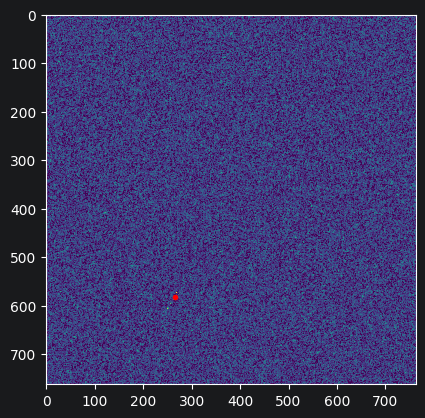

In [49]:
row, col = np.unravel_index(np.argmax(data[0]), data[0].shape)

plt.imshow(data[0], vmin=540, vmax=700)
plt.plot(col, row, 'r.')

In [50]:
hold = np.zeros_like(data[0])
for PI, I in enumerate(range(0,np.shape(data[0])[0],10)):
    for PJ, J in enumerate(range(0,np.shape(data[0])[1],10)):
        section = data[0][I:I+10,J:J+10]
        hold[PI,PJ]= np.mean(section)

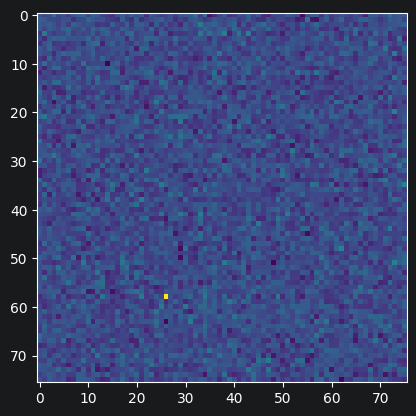

In [51]:
plt.imshow(hold[0:76,0:76])

In [85]:
frame_number = 2
from skimage.measure import ransac, LineModelND
data = load_tiff_frame("tracks_0.6_300.tif",frame_number)[0]
med = np.median(data)
mad = 1.4826*np.median(np.abs(data-med))
thr = max(np.percentile(data, 99.995), med + 8*mad)
y, x = np.nonzero(data > thr); pts = np.c_[x, y].astype(float)
model, inl = ransac(pts, LineModelND, min_samples=2, residual_threshold=2, max_trials=2000)


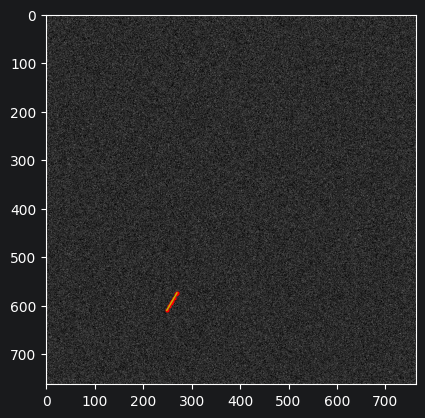

In [86]:
p0, d = model.params
ang = np.degrees(np.arctan2(-d[1], d[0])) % 180
# perpendicular distance of line from image centre
c = (np.array(data.shape[::-1])-1)/2; off = np.cross(d, c-p0)
t = (pts[inl]-p0)@d
#print(f'frame {i}: {len(pts)} pts, {inl.sum()} inliers, angle {ang:.1f} deg, centre offset {off:.1f}px, length {np.ptp(t):.0f}px')

plt.imshow(data, cmap='gray', vmin=500, vmax=900)
plt.plot(pts[~inl,0], pts[~inl,1], 'b.', ms=3)
plt.plot(pts[inl,0], pts[inl,1], 'r.', ms=4)
e = p0 + np.outer([t.min(), t.max()], d)
plt.plot(e[:,0], e[:,1], 'y-', lw=1)

